# 03 — Model Selection

**Wednesday.** Tuesday's single split gave one noisy opinion (83.2% vs 81.6% on 179 rows is within luck). Today: cross-validation for a trustworthy ranking, then honest error analysis before any tuning.

Sections:
1. Setup (same pipeline as notebook 02, refit fresh)
2. Cross-validation of the top-2 candidates
3. The dumb-rule baseline, properly compared
4. Confusion matrix — what the errors actually are
5. Conclusion → champion + challenger for tuning


## 1. Setup — refit fresh

Self-contained on purpose: this notebook must reproduce without running notebook 02 first. (The duplication disappears Thursday, when this code is promoted into `src/titanic/`.)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="darkgrid")
pd.set_option("display.max_columns", None)

RAW = Path("../data/raw")
RANDOM_STATE = 42

train = pd.read_csv(RAW / "train.csv")

RARE_TITLES = {"Dr", "Rev", "Col", "Major", "Capt", "Sir", "Lady", "Don", "Dona",
               "Countess", "Jonkheer", "Mme", "Ms", "Mlle"}

def extract_title(name: str) -> str:
    try:
        after_comma = name.split(",", 1)[1]
        title = after_comma.split(".", 1)[0].strip()
        return title if title.isalpha() else "Unknown"
    except IndexError:
        return "Unknown"

def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Title"] = df["Name"].map(extract_title).replace(list(RARE_TITLES), "Rare")
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
    df["HasCabin"] = df["Cabin"].notna().astype(int)
    return df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

train_fe = add_features(train)

NUMERIC = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "HasCabin"]
CATEGORICAL = ["Sex", "Embarked", "Title"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median"))]), NUMERIC),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), CATEGORICAL),
])

X = train_fe.drop(columns=["Survived"])
y = train_fe["Survived"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE,
)
print(f"train {X_train.shape} | val {X_val.shape}")

train (712, 11) | val (179, 11)


## 2. Cross-validation — one split is an anecdote, five is evidence

`cross_val_score` with a classifier defaults to **stratified 5-fold**: split the data into 5 folds, train on 4, score on 1, rotate — 5 scores from 5 *different* validation sets.

**Mean** = expected performance. **Std** = how much the score swings with the luck of the split — a direct read on variance (math checkpoint). A model that wins the mean with a small std is the dependable choice.

In [2]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

CANDIDATES = {
    "logistic_regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "gradient_boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv_rows = []
for name, model in CANDIDATES.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
    scores = cross_val_score(pipe, X, y, cv=5, scoring="accuracy")
    cv_rows.append({
        "model": name,
        "cv_mean": round(scores.mean(), 4),
        "cv_std": round(scores.std(), 4),
        "folds": [round(s, 3) for s in scores],
    })
    print(f"{name:22s} CV mean={scores.mean():.4f} ± {scores.std():.4f}  folds={[round(s,3) for s in scores]}")

cv_df = pd.DataFrame(cv_rows).sort_values("cv_mean", ascending=False)
cv_df

logistic_regression    CV mean=0.8272 ± 0.0260  folds=[np.float64(0.827), np.float64(0.809), np.float64(0.803), np.float64(0.82), np.float64(0.876)]


gradient_boosting      CV mean=0.8361 ± 0.0203  folds=[np.float64(0.849), np.float64(0.815), np.float64(0.86), np.float64(0.809), np.float64(0.848)]


,model,cv_mean,cv_std,folds
1,gradient_boosting,0.8361,0.0203,"[0.849, 0.815, 0.86, 0.809, 0.848]"
0,logistic_regression,0.8272,0.0260,"[0.827, 0.809, 0.803, 0.82, 0.876]"


## 3. The dumb-rule baseline, properly compared

Monday found "all women survive" = 78.7% on train. Before trusting any model number, place it next to the rule a human could apply in ten seconds. If the ML can't clearly beat the rule, the ML isn't adding value.

In [3]:
# the rule: female -> survive; male -> die. On OUR validation split, not train.
rule_pred_val = (X_val["Sex"] == "female").astype(int)
rule_acc_val = (rule_pred_val == y_val).mean()
print(f"dumb-rule accuracy on validation: {rule_acc_val:.3f}")

dumb-rule accuracy on validation: 0.777


## 4. Confusion matrix — accuracy hides everything

A single accuracy number answers "how often right?" A confusion matrix answers the more useful question: "**wrong how?**"

| | predicted survived | predicted died |
|---|---|---|
| **actually survived** | TP | **FN** ← "predicted dead, was alive" |
| **actually died** | FP ← "predicted alive, was dead" | TN |

For survival prediction, FN and FP are not equally bad — a markdown discussion follows the numbers.

champion by CV: gradient_boosting


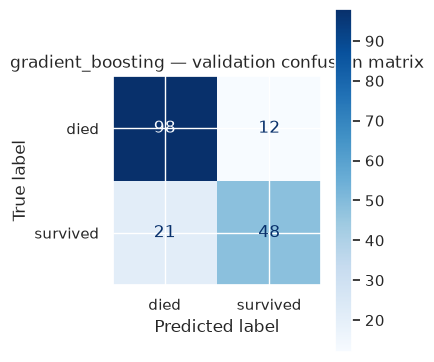

              precision    recall  f1-score   support

        died      0.824     0.891     0.856       110
    survived      0.800     0.696     0.744        69

    accuracy                          0.816       179
   macro avg      0.812     0.793     0.800       179
weighted avg      0.814     0.816     0.813       179



In [4]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

champion_name = cv_df.iloc[0]["model"]
champion = CANDIDATES[champion_name]

champ_pipe = Pipeline([("preprocess", preprocessor), ("model", champion)])
champ_pipe.fit(X_train, y_train)
val_pred = champ_pipe.predict(X_val)

print(f"champion by CV: {champion_name}")
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=["died", "survived"],
                                        cmap="Blues", ax=ax)
plt.title(f"{champion_name} — validation confusion matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_val, val_pred, target_names=["died", "survived"], digits=3))

## 5. Conclusion

**Cross-validation overturned Tuesday's single-split ranking — this is the whole point of the exercise.**

| model | Tuesday (1 split) | CV 5-fold | CV std |
|---|---|---|---|
| gradient_boosting | 0.816 | **0.8361** | **0.0203** |
| logistic_regression | **0.832** | 0.8272 | 0.0260 |

On 179 validation rows, 83.2% vs 81.6% was within shuffle luck. Across 5 folds, gradient boosting wins on **both** criteria: higher mean *and* lower variance (0.0203 vs 0.0260) — its scores are more dependable, fold to fold.

**Both models clear the real bar:** the dumb rule scores 77.7% on this same validation split. ML adds ~4–6 points over a human-applied rule — that is the value claim, stated honestly.

**Error analysis of the champion (gradient boosting, validation):**
- Survived-class **recall = 0.696**: of 69 actual survivors, ~21 were predicted to die (FN). The model misses 3 in 10 survivors.
- Survived-class **precision = 0.800**: of ~60 predicted survivors, ~12 were actually dead (FP).
- **Which error is worse?** Substantively, a false negative ("predicted dead, was alive") erases a survivor — but note for the Kaggle *metric* (pure accuracy), both errors cost the same. The asymmetry matters in real deployments, not in this score — worth saying out loud in an interview.

**Decision:** gradient_boosting is the **champion** (tuned in Task 7). logistic_regression stays as the **challenger/baseline** — a tuned fancy model must also beat the simple one on CV, or the tuning failed.
